# Book Market Analytics: Books to Scrape

**Module:** Data Science 500  
**Project:** Book Market Analytics  
**Dataset:** 220 books collected from Books to Scrape  
**Currency:** British pounds (GBP)

## Project overview

This notebook documents the workflow used to collect, clean, explore, visualise, and model book data. The sample was collected by starting in the **Young Adult** genre and continuing through subsequent genres until 220 unique books had been collected.

The main research questions are:

1. What does the distribution of book prices look like?
2. How do prices vary across ratings and genres?
3. What stock statuses appear in the collected sample?
4. Can a simple linear regression model predict book prices from rating and genre?

**Important:** This notebook expects `books_raw.csv` to be in the same folder as this notebook. It saves cleaned data, charts, summary statistics, regression metrics, and predictions in that folder.

## 1. Import libraries and set up folders

The libraries below are used for data handling, charts, and machine learning. If an import fails, install the missing package in a terminal, for example: `py -m pip install pandas matplotlib seaborn scikit-learn`.

In [1]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

BASE_DIR = Path.cwd()
GRAPHS_DIR = BASE_DIR / "graphs"
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

print("Working folder:", BASE_DIR)
print("Graphs folder:", GRAPHS_DIR)

Working folder: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500
Graphs folder: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500\graphs


## 2. Load the original dataset

The raw dataset should contain the book title, price, rating, stock information, genre, and source URL. We first inspect the number of records, column names, and first few rows.

In [2]:
raw_file = BASE_DIR / "books_raw.csv"

if not raw_file.exists():
    raise FileNotFoundError(
        "books_raw.csv was not found. Save this notebook in the same project folder "
        "as books_raw.csv, then run this cell again."
    )

raw_df = pd.read_csv(raw_file)
raw_df.columns = raw_df.columns.str.strip()

print("Original number of books:", len(raw_df))
print("\nColumns:")
print(raw_df.columns.tolist())
display(raw_df.head())

Original number of books: 220

Columns:
['title', 'price_gbp', 'rating_word', 'rating', 'stock_status', 'stock_quantity', 'genre', 'book_url']


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,genre,book_url
0,The Requiem Red,22.65,One,1,In stock,NaN,Young Adult,https://books.toscrape.com/the-requiem-red_995...
1,Set Me Free,17.46,Five,5,In stock,NaN,Young Adult,https://books.toscrape.com/set-me-free_988/ind...
2,The Natural History of Us (The Fine Art of Pre...,45.22,Three,3,In stock,NaN,Young Adult,https://books.toscrape.com/the-natural-history...
3,Obsidian (Lux #1),14.86,Two,2,In stock,NaN,Young Adult,https://books.toscrape.com/obsidian-lux-1_911/...
4,Burning,28.81,Three,3,In stock,NaN,Young Adult,https://books.toscrape.com/burning_884/index.html


## 3. Inspect data quality before cleaning

Missing values are counted in each column. The stock quantity field may be completely missing because the source provides a stock status rather than an exact quantity. We will not invent missing quantities.

In [3]:
print("Missing values before cleaning:")
display(raw_df.isna().sum().to_frame("missing_values"))

print("Duplicate rows:", raw_df.duplicated().sum())
if "title" in raw_df.columns:
    print("Duplicate titles:", raw_df["title"].duplicated().sum())

Missing values before cleaning:


,missing_values
title,0
price_gbp,0
rating_word,0
rating,0
stock_status,0
stock_quantity,220
genre,0
book_url,0


Duplicate rows: 0
Duplicate titles: 0


## 4. Clean the dataset

The cleaning steps standardise column names, convert numeric fields, map written ratings to numbers where necessary, standardise stock-status labels, mark missing genres as `Unknown`, and remove rows without a valid non-negative price or title. Missing stock quantities are kept missing because no exact values were collected.

In [4]:
df = raw_df.copy()

rename_candidates = {
    "price": "price_gbp",
    "price (£)": "price_gbp",
    "rating_number": "rating",
    "star_rating": "rating",
    "stock": "stock_status",
    "availability": "stock_status",
    "quantity": "stock_quantity",
    "stock_qty": "stock_quantity",
    "category": "genre",
}
for old_name, new_name in rename_candidates.items():
    if old_name in df.columns and new_name not in df.columns:
        df.rename(columns={old_name: new_name}, inplace=True)

# Add expected columns if a source field is absent.
for column in ["title", "price_gbp", "rating", "rating_word",
               "stock_status", "stock_quantity", "genre"]:
    if column not in df.columns:
        df[column] = pd.NA

for column in ["title", "rating_word", "stock_status", "genre"]:
    df[column] = df[column].astype("string").str.strip()

for column in ["price_gbp", "rating", "stock_quantity"]:
    df[column] = pd.to_numeric(
        df[column].astype("string").str.replace("£", "", regex=False),
        errors="coerce"
    )

rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
mapped_ratings = df["rating_word"].map(rating_map)
df["rating"] = df["rating"].fillna(mapped_ratings)

df["stock_status"] = (
    df["stock_status"].str.lower().str.strip()
    .map({
        "in stock": "In stock",
        "out of stock": "Out of stock",
        "available": "In stock",
        "unavailable": "Out of stock",
    })
    .fillna("Unknown")
)

df["genre"] = df["genre"].fillna("Unknown").replace("", "Unknown")
df["title"] = df["title"].fillna("Untitled").replace("", "Untitled")

before_dedup = len(df)
if "title" in df.columns:
    df = df.drop_duplicates(subset=["title"], keep="first")

df = df.dropna(subset=["price_gbp"])
df = df[df["price_gbp"] >= 0].copy()
df.loc[~df["rating"].between(1, 5), "rating"] = pd.NA
df.loc[df["stock_quantity"] < 0, "stock_quantity"] = pd.NA

print("Records before title deduplication:", before_dedup)
print("Cleaned records:", len(df))
print("Duplicate titles removed:", before_dedup - df["title"].nunique())
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("missing_values"))

cleaned_file = BASE_DIR / "books_cleaned.csv"
df.to_csv(cleaned_file, index=False)
print("Saved cleaned dataset:", cleaned_file)
display(df.head())

Records before title deduplication: 220
Cleaned records: 220
Duplicate titles removed: 0

Missing values after cleaning:


,missing_values
title,0
price_gbp,0
rating_word,0
rating,0
stock_status,0
stock_quantity,220
genre,0
book_url,0


Saved cleaned dataset: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500\books_cleaned.csv


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,genre,book_url
0,The Requiem Red,22.65,One,1,In stock,<NA>,Young Adult,https://books.toscrape.com/the-requiem-red_995...
1,Set Me Free,17.46,Five,5,In stock,<NA>,Young Adult,https://books.toscrape.com/set-me-free_988/ind...
2,The Natural History of Us (The Fine Art of Pre...,45.22,Three,3,In stock,<NA>,Young Adult,https://books.toscrape.com/the-natural-history...
3,Obsidian (Lux #1),14.86,Two,2,In stock,<NA>,Young Adult,https://books.toscrape.com/obsidian-lux-1_911/...
4,Burning,28.81,Three,3,In stock,<NA>,Young Adult,https://books.toscrape.com/burning_884/index.html


## 5. Descriptive statistics

The descriptive statistics summarise the price variable and show how prices vary across the collected books. These results describe this sample; they should not automatically be generalised to every book or online bookstore.

In [5]:
print("Number of books:", len(df))
print("Genres represented:", df["genre"].nunique())
print("\nPrice summary (GBP):")
display(df["price_gbp"].describe().round(2).to_frame("price_gbp"))

summary = df[["price_gbp", "rating", "stock_quantity"]].describe().round(2)
summary.to_csv(BASE_DIR / "summary_statistics.csv")
print("Saved summary_statistics.csv")

print("Books by genre:")
display(df["genre"].value_counts().to_frame("book_count"))

Number of books: 220
Genres represented: 17

Price summary (GBP):


,price_gbp
count,220.0
mean,34.41
std,14.71
min,10.0
25%,21.34
50%,35.49
75%,46.91
max,59.95


Saved summary_statistics.csv
Books by genre:


,book_count
genre,
Young Adult,54
Food and Drink,30
Poetry,19
History,18
Horror,17
Science,14
Business,12
Humor,10
Autobiography,9


## 6. Visualise the data

The following charts examine price distribution, rating and price, price differences between ratings, stock status, average price by genre, and the number of books in each genre. Charts are saved to the `graphs` folder.

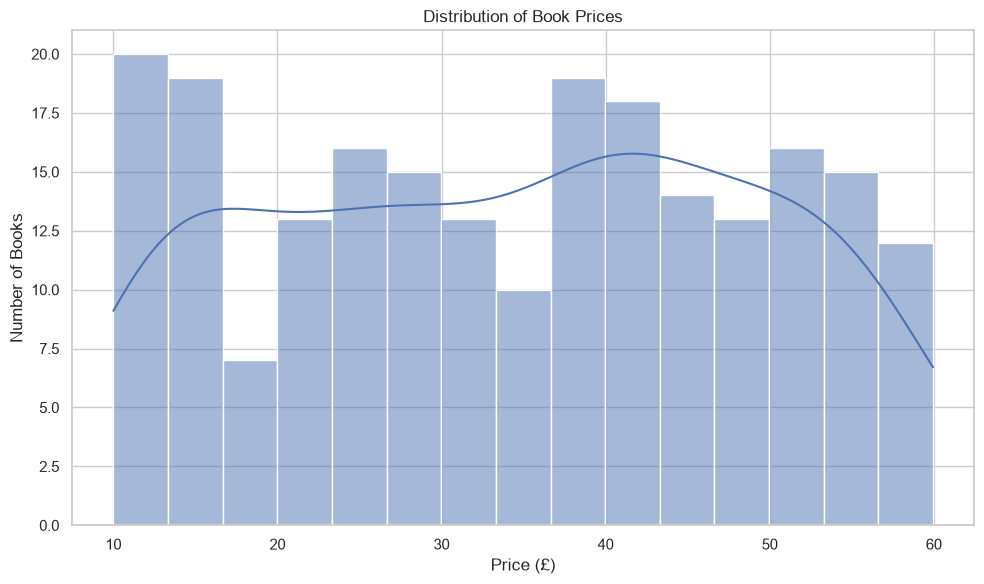

In [6]:
# Graph 1: Price distribution histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="price_gbp", bins=15, kde=True)
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "01_price_distribution_histogram.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

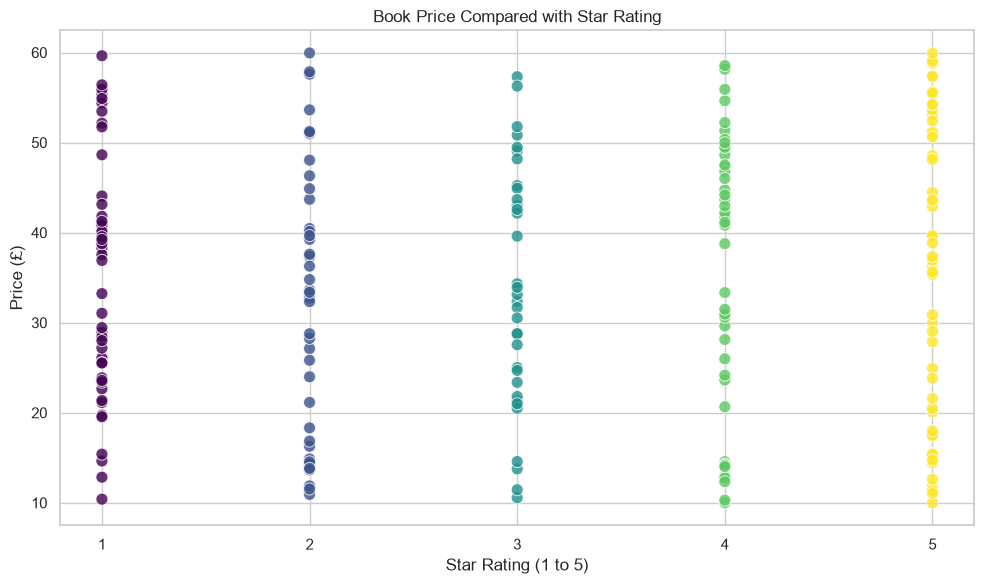

In [7]:
# Graph 2: Rating versus price scatter plot
scatter_df = df.dropna(subset=["rating", "price_gbp"])
plt.figure(figsize=(10, 6))
if not scatter_df.empty:
    sns.scatterplot(data=scatter_df, x="rating", y="price_gbp", hue="rating", palette="viridis", s=75, alpha=0.8, legend=False)
    plt.xticks([1, 2, 3, 4, 5])
else:
    plt.text(0.5, 0.5, "No valid ratings available", ha="center", va="center", transform=plt.gca().transAxes)
plt.title("Book Price Compared with Star Rating")
plt.xlabel("Star Rating (1 to 5)")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "02_price_vs_rating_scatter.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

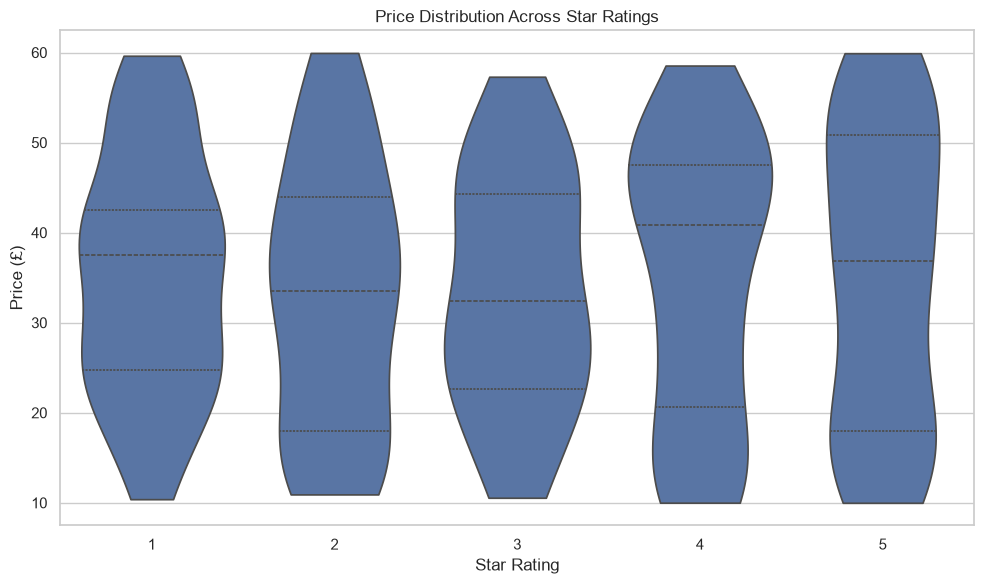

In [8]:
# Graph 3: Price distribution across star ratings
violin_df = df.dropna(subset=["rating", "price_gbp"]).copy()
plt.figure(figsize=(10, 6))
if not violin_df.empty and violin_df["rating"].nunique() >= 2:
    violin_df["rating"] = violin_df["rating"].astype(int).astype(str)
    rating_order = [str(n) for n in range(1, 6) if str(n) in violin_df["rating"].unique()]
    sns.violinplot(data=violin_df, x="rating", y="price_gbp", order=rating_order, inner="quartile", cut=0)
else:
    plt.text(0.5, 0.5, "A violin plot needs valid prices across at least two rating groups.", ha="center", va="center", wrap=True, transform=plt.gca().transAxes)
plt.title("Price Distribution Across Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "03_price_by_rating_violin.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

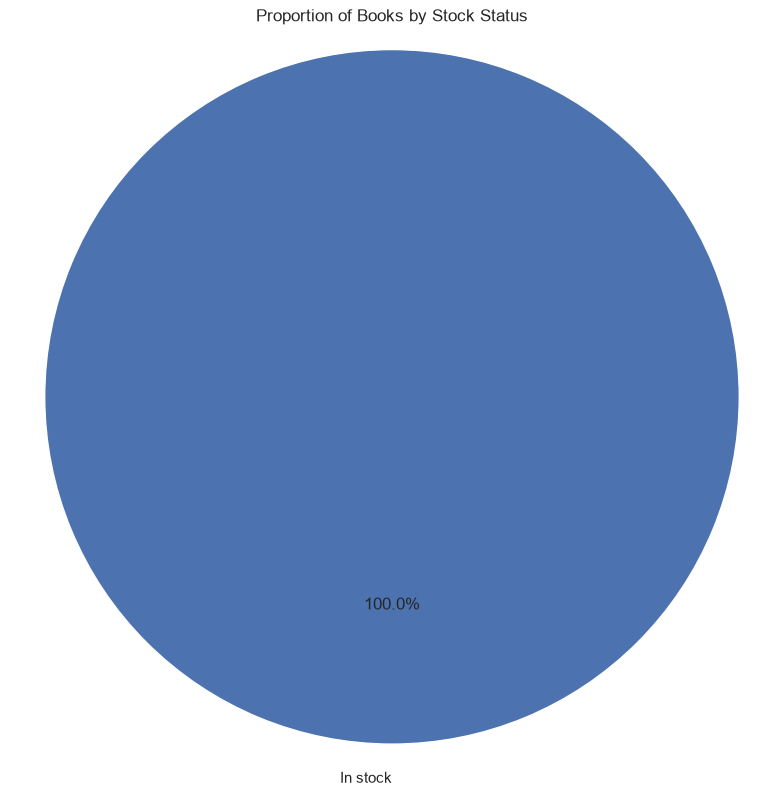

In [9]:
# Graph 4: Stock status pie chart
stock_counts = df["stock_status"].value_counts()
plt.figure(figsize=(8, 8))
if not stock_counts.empty:
    plt.pie(stock_counts.values, labels=stock_counts.index, autopct="%1.1f%%", startangle=90)
    plt.axis("equal")
else:
    plt.text(0.5, 0.5, "No stock status data available", ha="center", va="center", transform=plt.gca().transAxes)
plt.title("Proportion of Books by Stock Status")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "04_stock_status_pie.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

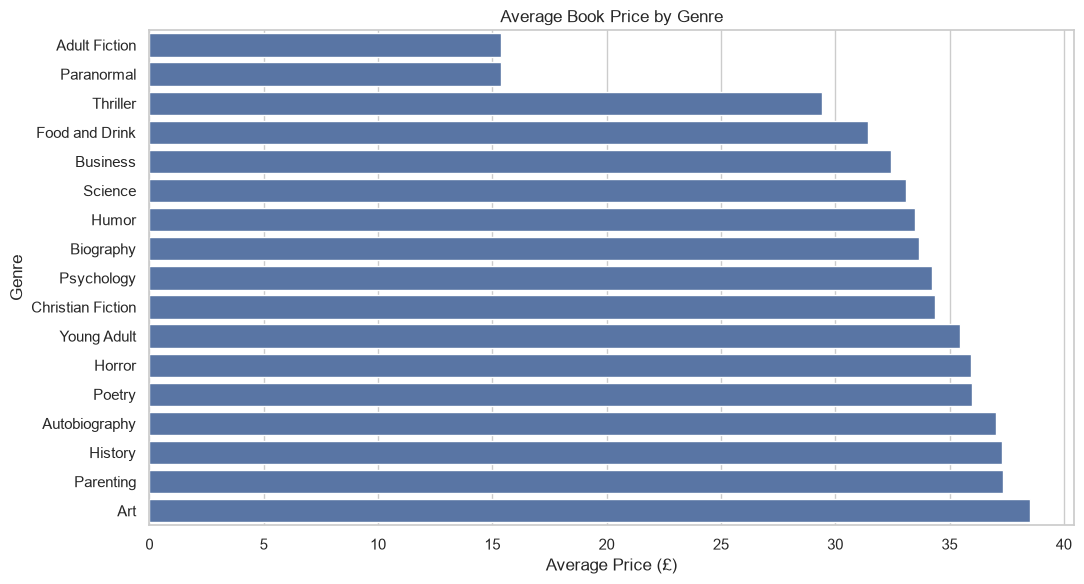

In [10]:
# Graph 5: Average price by genre
genre_prices = (
    df[df["genre"] != "Unknown"]
    .groupby("genre")["price_gbp"]
    .mean()
    .sort_values()
)
plt.figure(figsize=(11, max(6, 0.35 * max(len(genre_prices), 1))))
if not genre_prices.empty:
    sns.barplot(x=genre_prices.values, y=genre_prices.index, orient="h")
plt.title("Average Book Price by Genre")
plt.xlabel("Average Price (£)")
plt.ylabel("Genre")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "05_average_price_by_genre.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

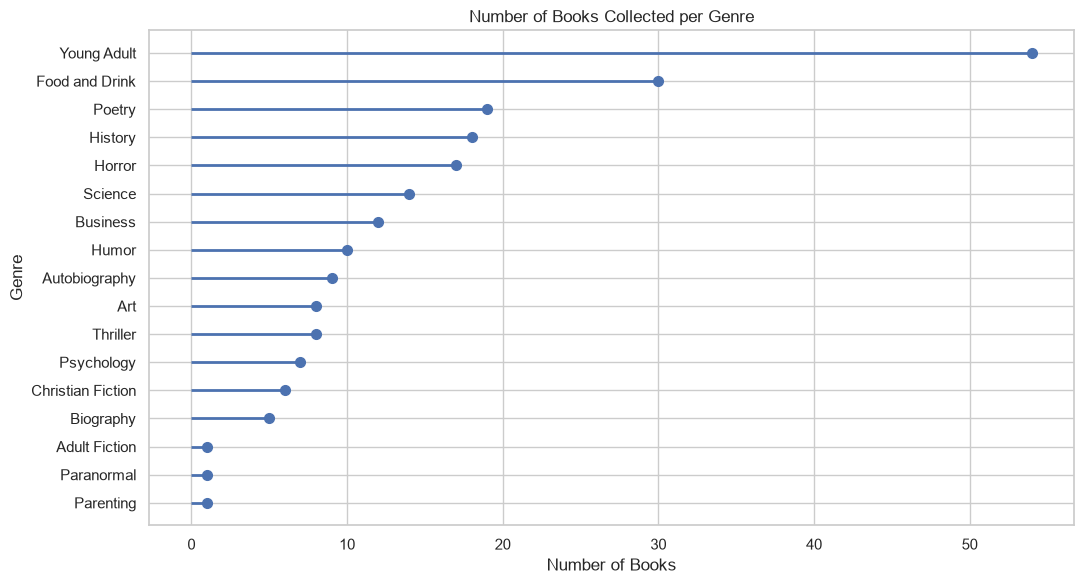

In [11]:
# Graph 6: Number of books by genre (lollipop chart)
genre_counts = df[df["genre"] != "Unknown"]["genre"].value_counts().sort_values()
plt.figure(figsize=(11, max(6, 0.35 * max(len(genre_counts), 1))))
if not genre_counts.empty:
    positions = range(len(genre_counts))
    plt.hlines(y=list(positions), xmin=0, xmax=genre_counts.values, linewidth=2)
    plt.plot(genre_counts.values, list(positions), "o", markersize=7)
    plt.yticks(list(positions), genre_counts.index)
plt.title("Number of Books Collected per Genre")
plt.xlabel("Number of Books")
plt.ylabel("Genre")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "06_books_by_genre_lollipop.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### 6.1 Correlation heatmap

The heatmap uses numeric columns with sufficient non-missing values and variation. Because `stock_quantity` is entirely missing in the current dataset, it is excluded automatically.

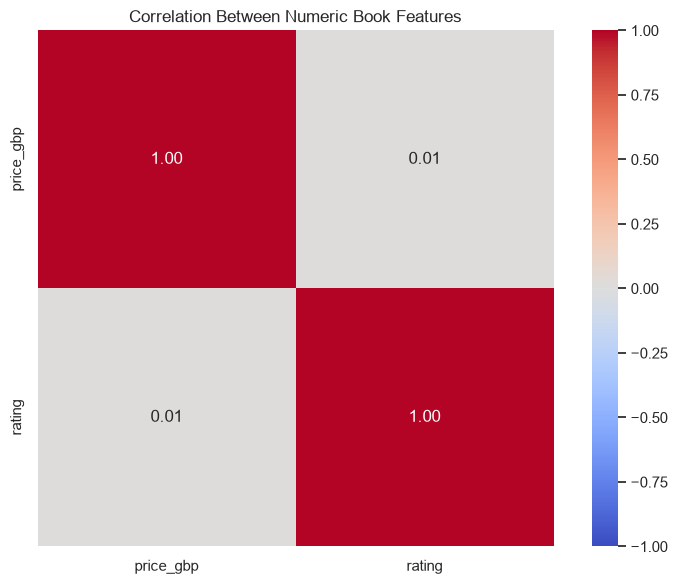

,price_gbp,rating
price_gbp,1.000000,0.013923
rating,0.013923,1.000000


In [12]:
numeric_columns = ["price_gbp", "rating", "stock_quantity"]
numeric_data = df[numeric_columns].copy()
usable_columns = [
    col for col in numeric_data.columns
    if numeric_data[col].notna().sum() >= 3 and numeric_data[col].nunique(dropna=True) >= 2
]

if len(usable_columns) >= 2:
    corr_data = numeric_data[usable_columns].dropna()
    if len(corr_data) >= 3:
        corr = corr_data.corr(numeric_only=True)
        plt.figure(figsize=(8, 6))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
        plt.title("Correlation Between Numeric Book Features")
        plt.tight_layout()
        plt.savefig(GRAPHS_DIR / "07_correlation_heatmap.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()
        display(corr)
    else:
        print("Correlation heatmap skipped: not enough complete numeric records.")
else:
    print("Correlation heatmap skipped: fewer than two usable numeric columns.")

## 7. Linear regression: predicting book price

This baseline model uses **rating** and **genre** as input features and `price_gbp` as the target. Genre is categorical, so it is converted into numeric indicator columns using one-hot encoding. Missing ratings are imputed using the median rating from the training data.

The data is split into 80% training records and 20% test records. The test set is used to evaluate predictions on records not used to fit the model. With only 220 books and a limited set of predictors, the model may not predict prices accurately.

In [13]:
model_df = df.dropna(subset=["price_gbp"]).copy()
model_df = model_df[model_df["price_gbp"] >= 0]
model_df["rating"] = pd.to_numeric(model_df["rating"], errors="coerce")
model_df["genre"] = model_df["genre"].fillna("Unknown").astype(str)

features = ["rating", "genre"]
target = "price_gbp"

X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_features = ["rating"]
categorical_features = ["genre"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "metric": ["MAE", "RMSE", "R2"],
    "value": [mae, rmse, r2]
})
metrics.to_csv(BASE_DIR / "regression_metrics.csv", index=False)

predictions = X_test.copy()
predictions["actual_price_gbp"] = y_test.values
predictions["predicted_price_gbp"] = y_pred
predictions["absolute_error_gbp"] = abs(predictions["actual_price_gbp"] - predictions["predicted_price_gbp"])
predictions.to_csv(BASE_DIR / "books_price_predictions.csv", index=False)

print("LINEAR REGRESSION MODEL")
print("-" * 40)
print("Books used for model:", len(model_df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")
print("\nSaved regression_metrics.csv")
print("Saved books_price_predictions.csv")
display(metrics)
display(predictions.head())

LINEAR REGRESSION MODEL
----------------------------------------
Books used for model: 220
Training records: 176
Testing records: 44
Mean Absolute Error (MAE): £14.31
Root Mean Squared Error (RMSE): £16.48
R-squared (R²): -0.065

Saved regression_metrics.csv
Saved books_price_predictions.csv


,metric,value
0,MAE,14.314872
1,RMSE,16.484254
2,R2,-0.065054


,rating,genre,actual_price_gbp,predicted_price_gbp,absolute_error_gbp
132,5,Horror,35.63,36.176930,0.54693
148,3,History,21.8,37.628274,15.828274
93,4,Art,41.14,37.906330,3.23367
180,2,Food and Drink,28.25,32.689949,4.439949
15,1,Young Adult,55.35,34.773120,20.57688


### 7.1 Actual versus predicted prices

Points close to the diagonal represent predictions close to actual prices. Large gaps indicate prediction errors. This graph helps visually assess model performance.

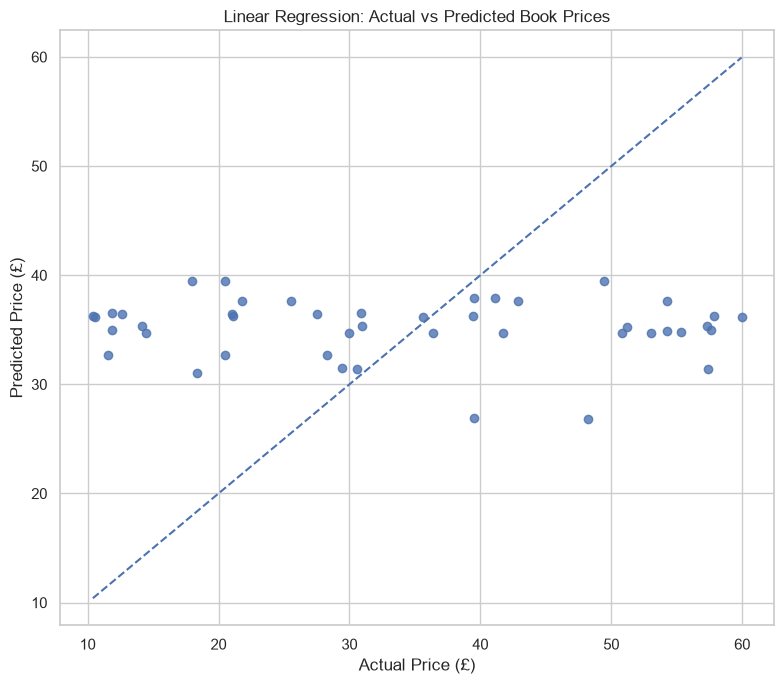

Saved graphs/08_regression_actual_vs_predicted.png


In [14]:
plt.figure(figsize=(8, 7))
plt.scatter(y_test, y_pred, alpha=0.8)
low = min(float(y_test.min()), float(np.min(y_pred)))
high = max(float(y_test.max()), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.title("Linear Regression: Actual vs Predicted Book Prices")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "08_regression_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Saved graphs/08_regression_actual_vs_predicted.png")

## 8. Interpretation and limitations

Use the results generated above to write evidence-based conclusions. Do not assume that ratings cause higher prices.

Points to discuss:

- The average, median, minimum, and maximum prices describe the collected sample.
- Genre counts may be uneven because collection stopped as soon as 220 unique books were reached.
- The model uses rating and genre only. Other potentially useful variables were not included.
- A negative R² means the model performs worse on the test set than a baseline that predicts the mean training price for each test observation.
- MAE gives the average absolute error in pounds, while RMSE penalises larger errors more strongly.
- The `stock_quantity` field is missing for all books in the current scrape. It should be reported as unavailable rather than filled with invented numbers.
- The results describe this sample from Books to Scrape and may not represent the entire book market.

## 9. Save final output and verify the files

The final output should include `books_cleaned.csv`, `summary_statistics.csv`, `regression_metrics.csv`, `books_price_predictions.csv`, and the chart images in `graphs/`.

In [15]:
print("NOTEBOOK RUN COMPLETE")
print("Books analysed:", len(df))
print("Genres represented:", df["genre"].nunique())
print("Cleaned dataset:", BASE_DIR / "books_cleaned.csv")
print("Summary statistics:", BASE_DIR / "summary_statistics.csv")
print("Regression metrics:", BASE_DIR / "regression_metrics.csv")
print("Predictions:", BASE_DIR / "books_price_predictions.csv")
print("Graphs folder:", GRAPHS_DIR)

NOTEBOOK RUN COMPLETE
Books analysed: 220
Genres represented: 17
Cleaned dataset: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500\books_cleaned.csv
Summary statistics: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500\summary_statistics.csv
Regression metrics: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500\regression_metrics.csv
Predictions: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500\books_price_predictions.csv
Graphs folder: c:\Users\ICMOTN\OneDrive\Documents\Richfield Docs\402604638 DataScience 500\graphs
